# T-RAG · Notebook 7 — Which search methods mix up the years? (~5 minutes)

## About this notebook

**What it does :** Notebook 2 showed that semantic (vector) search mixes up the years. This notebook checks whether the other search methods inside standard RAG do better. It repeats the same test with each method, on Notebook 4's index and with Notebook 5's exact settings. For each company and year, it asks "What happened to Tesla in 2022?" with no date filter, and counts how many of the top 20 results really come from that year. The share is 68% for semantic search, 72% for keyword search (BM25), 77% for hybrid search and 91% for hybrid + reranker. Random picking gives 45%. So even the best method leaves 9% from the wrong year, and this is its easiest case, because the year is written in the question.

A second test uses a realistic question with no year in it: "What is the latest news about Tesla?", asked at the start of each quarter from April 2022 to October 2023. Without a date filter, 41–47% of the top 20 results are from after the as-of date, which is information the user could not have had. Only 3–5% are from the last four weeks. Both shares are about what random picking gives. This is why T-RAG uses explicit time rules instead of hoping that search understands time.

**Needs :** Notebook 4's output. No GPU needed. Internet on. About a minute to run.

**Produces :** `trag_timeblind/` with result tables (CSV and JSON) and two charts.

In [1]:
from pathlib import Path
import re, json, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.feature_extraction.text import CountVectorizer
from scipy import sparse
from sentence_transformers import SentenceTransformer, CrossEncoder
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)

RERANK_MODEL = "BAAI/bge-reranker-base"
TOP_N, N_EACH, N_RERANK, RRF_K, TOP_K_B2 = 20, 100, 50, 60, 8
YEARS, MIN_DOCS = (2022, 2023), 200            # same rule as Notebook 2: both years need >= 200 news articles
NAMES = {"TSLA": "Tesla", "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "Nvidia", "AMZN": "Amazon",
         "META": "Meta", "GOOGL": "Alphabet (Google)", "NFLX": "Netflix", "AMD": "AMD", "INTC": "Intel"}   # Notebook 2's wording
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT = Path("/kaggle/working/trag_timeblind") if Path("/kaggle/working").exists() else Path("trag_timeblind")
OUT.mkdir(parents=True, exist_ok=True)
T0 = time.time()

def need(name, folder="trag_index_v2"):
    hits = sorted(glob.glob(f"/kaggle/input/**/{folder}/{name}", recursive=True)) + sorted(glob.glob(f"{folder}/{name}"))
    if not hits: raise FileNotFoundError(f"{folder}/{name} not found — attach Notebook 4's output (Add Data → Notebook Output Files).")
    return hits[0]

chunks = pd.read_parquet(need("chunks_v2.parquet"))
E = np.load(need("embeddings_v2.npy")).astype(np.float32)
assert len(chunks) == len(E), "chunks and embeddings are out of sync"
manifest = json.loads(Path(need("manifest_v2.json")).read_text())
EMBED_MODEL, QUERY_PREFIX = manifest["embedder"], manifest["query_prefix"]
CHUNK_TEXT = chunks.chunk_text.astype(str).values
TICK, SRC = chunks.ticker.astype(str).values, chunks.source.astype(str).values
YEAR = pd.to_datetime(chunks.day0).dt.year.values
print(f"{len(chunks):,} documents", chunks.source.value_counts().to_dict(), "| device:", DEVICE)
print("Example chunk:", CHUNK_TEXT[np.flatnonzero(SRC == "news")[0]][:120], "…")

108,054 documents {'social': 57516, 'news': 49993, 'filing': 521, 'fed': 24} | device: cuda
Example chunk: [INTC | 2021-01-04 | nasdaq.com] 3 Top Mega-Cap Stocks to Own in 2021. Three Fool.com contributors think salesforce.com  …


## Step 1 — Build the keyword index exactly as standard RAG does

The line printed below shows the words BM25 sees in a document header. A date such as `2022-05-03` is split into `2022`, `05` and `03`, so the word **2022** in the question can match the header of every 2022 article.

In [2]:
cv = CountVectorizer(lowercase=True, stop_words="english", min_df=2, dtype=np.float32)
Xc = cv.fit_transform(CHUNK_TEXT)
dl = np.asarray(Xc.sum(axis=1)).ravel(); avgdl = dl.mean(); N_DOCS = Xc.shape[0]
dfreq = np.asarray((Xc > 0).sum(axis=0)).ravel()
idf = np.log(1 + (N_DOCS - dfreq + 0.5) / (dfreq + 0.5))
Xo = Xc.tocoo(); k1, b = 1.5, 0.75
W = sparse.csc_matrix((Xo.data * (k1 + 1) / (Xo.data + k1 * (1 - b + b * dl[Xo.row] / avgdl)) * idf[Xo.col],
                       (Xo.row, Xo.col)), shape=Xc.shape)
del Xc, Xo
VOC = cv.vocabulary_
def bm25(query):
    cols = cv.transform([query]).indices
    return np.asarray(W[:, cols].sum(axis=1)).ravel() if len(cols) else np.zeros(N_DOCS, np.float32)

analyzer = cv.build_analyzer()
print(f"BM25 index: {N_DOCS:,} documents × {W.shape[1]:,} terms")
print("Words BM25 sees in a header :", analyzer(CHUNK_TEXT[np.flatnonzero(SRC == 'news')[0]].split(']')[0] + ']'))
print("Words BM25 sees in the question :", analyzer("What happened to Tesla in 2022?"))
for w in ("2022", "2023", "happened", "tesla"):
    if w in VOC:
        print(f"  '{w}': in {int(dfreq[VOC[w]]):,} documents, weight (idf) {idf[VOC[w]]:.2f}")

emb = SentenceTransformer(EMBED_MODEL, device=DEVICE)
ce = CrossEncoder(RERANK_MODEL, device=DEVICE, max_length=512)
if DEVICE == "cuda":
    emb = emb.half()
    try: ce.model.half()
    except Exception: pass

BM25 index: 108,054 documents × 38,170 terms
Words BM25 sees in a header : ['intc', '2021', '01', '04', 'nasdaq', 'com']
Words BM25 sees in the question : ['happened', 'tesla', '2022']
  '2022': in 59,489 documents, weight (idf) 0.60
  '2023': in 32,354 documents, weight (idf) 1.21
  'happened': in 1,145 documents, weight (idf) 4.55
  'tesla': in 25,168 documents, weight (idf) 1.46


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

... (14 outputs left out)

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

## Step 2 — The test, with each search method

Same questions and same rule as Notebook 2. For every method we keep the top 20 results and count how many come from the year asked. **Chance** = that year's share of the company's news (what random picking would give). Ties in a score are broken at random (fixed seed), so the order of the files cannot help any method.

In [3]:
rng = np.random.default_rng(0)
TIEBREAK = rng.random(N_DOCS)

def ranked(idx, score):
    """idx sorted by score (high first); ties broken by a fixed random key."""
    return idx[np.lexsort((TIEBREAK[idx], -score[idx]))]

def rrf(*lists):
    acc = {}
    for lst in lists:
        for r, c in enumerate(lst):
            acc[c] = acc.get(c, 0.0) + 1.0 / (RRF_K + r + 1)
    return np.array(sorted(acc, key=lambda c: (-acc[c], TIEBREAK[c])), dtype=np.int64)

def share(top, y):
    return float((YEAR[top] == y).mean()) if len(top) else np.nan

rows, examples = [], []
news_tickers = [t for t in NAMES if ((TICK == t) & (SRC == "news")).sum() > 0]
for t in news_tickers:
    idx_t = np.flatnonzero((TICK == t) & (SRC == "news"))
    for y in YEARS:
        in_y = YEAR[idx_t] == y
        if in_y.sum() < MIN_DOCS or (~in_y).sum() < MIN_DOCS:
            continue
        q = f"What happened to {NAMES[t]} in {y}?"
        qv = emb.encode([QUERY_PREFIX + q], normalize_embeddings=True)[0].astype(np.float32)
        dn, bm = E @ qv, bm25(q)
        sem = ranked(idx_t, dn); kw = ranked(idx_t, bm)
        hyb = rrf(kw[:N_EACH], sem[:N_EACH])
        cand = hyb[:N_RERANK]
        rr = np.asarray(ce.predict([(q, CHUNK_TEXT[i]) for i in cand], batch_size=32, show_progress_bar=False), np.float32)
        rer = cand[np.lexsort((TIEBREAK[cand], -rr))]
        rows.append({"company": t, "year asked": y, "chance": round(float(in_y.mean()), 3),
                     "semantic": share(sem[:TOP_N], y), "keyword": share(kw[:TOP_N], y),
                     "hybrid": share(hyb[:TOP_N], y), "hybrid + reranker": share(rer[:TOP_N], y),
                     "standard RAG top 8": share(rer[:TOP_K_B2], y),
                     "keyword: top-20 docs containing the year": int(sum(str(y) in CHUNK_TEXT[i].split("]", 1)[-1] for i in kw[:TOP_N]))})
        examples.append((t, y, [(str(pd.Timestamp(chunks.day0.iloc[i]).date()), CHUNK_TEXT[i][:110]) for i in kw[:3]]))
res = pd.DataFrame(rows)
METHODS = ["semantic", "keyword", "hybrid", "hybrid + reranker"]
print(res.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"\n{len(res)} company-year questions | {time.time()-T0:.0f}s")

company  year asked  chance  semantic  keyword  hybrid  hybrid + reranker  standard RAG top 8  keyword: top-20 docs containing the year
   TSLA        2022    0.37      0.65     0.95    0.80               0.95                0.88                                         2
   TSLA        2023    0.63      0.75     1.00    0.90               1.00                1.00                                         7
   AAPL        2022    0.35      0.45     0.85    0.55               0.80                0.75                                         1
   AAPL        2023    0.65      0.90     0.90    0.95               0.95                0.88                                         1
   MSFT        2022    0.31      0.40     0.65    0.80               0.85                0.88                                         2
   MSFT        2023    0.69      0.80     0.85    0.90               1.00                1.00                                         1
   NVDA        2022    0.28      0.70     0.75  

## Step 3 — Summary, chart and the sentence for the slide

                   share of top 20 from the year asked  pairs above chance
chance                                           0.445                 NaN
semantic                                         0.679                14.0
keyword                                          0.725                14.0
hybrid                                           0.771                14.0
hybrid + reranker                                0.914                14.0

Standard RAG reads only its top 8: 92% of those come from the year asked.
Semantic search here: 67.9% (Notebook 2 reported 67.9% on its own copy of the index; small differences are normal).

Top 3 keyword results for the first question (date shown first):
  2022-12-15  [TSLA | 2022-12-15 | nasdaq.com] Why Tesla Shares Have Been Sinking This Week. What happened The major U.S. st
  2022-05-05  [TSLA | 2022-05-05 | nasdaq.com] Why Tesla Stock Crashed Today. What happened Tesla (NASDAQ: TSLA) stock crash
  2022-05-20  [TSLA | 2022-05-20 | nasdaq.c

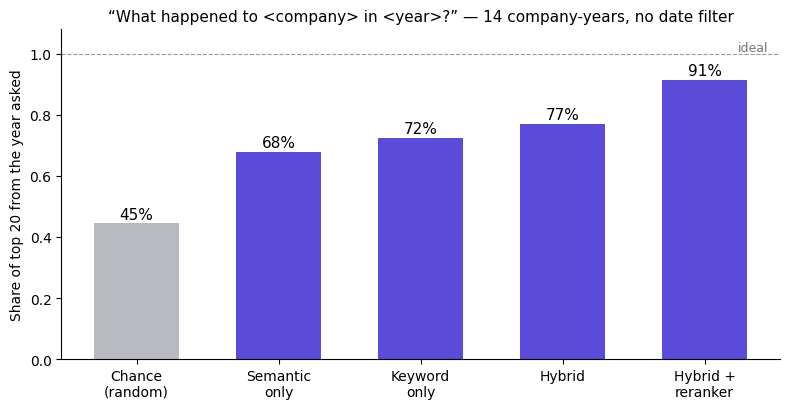


For the slide / report:
  Share of the top 20 results from the year asked (chance 45%): semantic 68%, keyword 72%, hybrid 77%, hybrid + reranker 91%.
  Even the best method here (hybrid + reranker) leaves 9% of results from the wrong year, although this question names the year, which is the easiest case for keyword search.


In [4]:
mean = res[["chance"] + METHODS + ["standard RAG top 8"]].mean()
above = {m: int((res[m] > res["chance"]).sum()) for m in METHODS}
summary = pd.DataFrame({"share of top 20 from the year asked": mean[["chance"] + METHODS].round(3),
                        "pairs above chance": pd.Series({"chance": np.nan, **above})})
print(summary.to_string())
print(f"\nStandard RAG reads only its top 8: {mean['standard RAG top 8']:.0%} of those come from the year asked.")
print(f"Semantic search here: {mean['semantic']:.1%} (Notebook 2 reported 67.9% on its own copy of the index; small differences are normal).")
res.to_csv(OUT / "timeblind_by_method.csv", index=False)
summary.to_csv(OUT / "timeblind_summary.csv")

print("\nTop 3 keyword results for the first question (date shown first):")
for t, y, ex in examples[:1]:
    for d, txt in ex: print(f"  {d}  {txt}")

labels = ["Chance\n(random)", "Semantic\nonly", "Keyword\nonly", "Hybrid", "Hybrid +\nreranker"]
vals = [mean["chance"]] + [mean[m] for m in METHODS]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(labels, vals, color=["#B9B9C2", "#5B4BDB", "#5B4BDB", "#5B4BDB", "#5B4BDB"], width=0.6)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v:.0%}", ha="center", fontsize=11)
ax.axhline(1.0, color="#999", lw=0.8, ls="--"); ax.text(4.45, 1.01, "ideal", fontsize=9, color="#777", ha="right")
ax.set_ylim(0, 1.08); ax.set_ylabel("Share of top 20 from the year asked")
ax.set_title(f"“What happened to <company> in <year>?” — {len(res)} company-years, no date filter", fontsize=11)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "timeblind_by_method.png", dpi=200); plt.show()

best = max(METHODS, key=lambda m: mean[m])
print("\nFor the slide / report:")
print(f"  Share of the top 20 results from the year asked (chance {mean['chance']:.0%}): "
      + ", ".join(f"{m} {mean[m]:.0%}" for m in METHODS) + ".")
if 1 - mean[best] >= 0.05:
    print(f"  Even the best method here ({best}) leaves {1 - mean[best]:.0%} of results from the wrong year,"
          " although this question names the year, which is the easiest case for keyword search.")
else:
    print(f"  {best} gets the year right because the question names it and every header carries the date."
          " Real questions rarely name the year: see Step 4.")
SUMMARY = {"year_test": {"pairs": len(res), "mean": {k: round(float(v), 4) for k, v in mean.items()}, "pairs_above_chance": above}}

## Step 4 — A realistic question with no year in it: "What is the latest news about X?"

Real questions rarely contain the year as a word. Here we ask *"What is the latest news about {company}?"* at the start of every quarter from April 2022 to October 2023 (the **as-of date**), again with **no date filter**, exactly as standard RAG searches (in Notebook 5 too, the "As of <date>," part of a question is not part of the search text). For each method we measure, in the top 20:
- **from the future :** published after the as-of date (information the user could not have had);
- **from the last four weeks :** published in the 28 days before the as-of date (what "latest" means).

*Chance* = the same shares for random picking from the company's news.

49 company / as-of date pairs
                  from the future from the last 4 weeks
chance                     50.4 %                 3.8 %
semantic                   46.7 %                 5.3 %
keyword                    40.5 %                 3.4 %
hybrid                     47.0 %                 4.5 %
hybrid + reranker          47.4 %                 4.5 %

For the slide / report:
  Asked for the latest news with no date filter, the top 20 results contain semantic 47%, keyword 41%, hybrid 47%, hybrid + reranker 47% documents from after the as-of date, and only 5%, 3%, 4%, 4% from the last four weeks (same order).


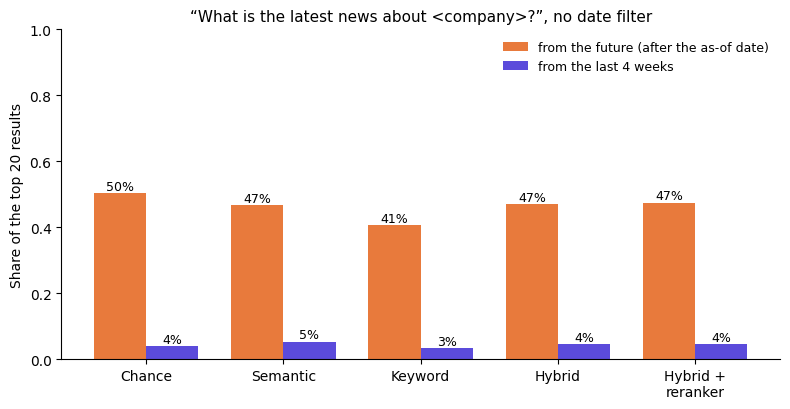


Done in 34s
latest_news_by_method.csv               4.7 KB
latest_news_by_method.png              73.7 KB
timeblind_by_method.csv                 0.7 KB
timeblind_by_method.png                76.8 KB
timeblind_summary.csv                   0.2 KB
timeblind_summary.json                  0.9 KB


In [5]:
AV = pd.to_datetime(chunks.available_at, utc=True).values.astype("datetime64[ns]").astype(np.int64)
DAY = 86_400 * 10**9
AS_OF_DATES = pd.date_range("2022-04-01", "2023-10-01", freq="QS")
rows2 = []
for t in news_tickers:
    idx_t = np.flatnonzero((TICK == t) & (SRC == "news"))
    q = f"What is the latest news about {NAMES[t]}?"
    qv = emb.encode([QUERY_PREFIX + q], normalize_embeddings=True)[0].astype(np.float32)
    dn, bm = E @ qv, bm25(q)
    sem = ranked(idx_t, dn); kw = ranked(idx_t, bm); hyb = rrf(kw[:N_EACH], sem[:N_EACH])
    cand = hyb[:N_RERANK]
    rr = np.asarray(ce.predict([(q, CHUNK_TEXT[i]) for i in cand], batch_size=32, show_progress_bar=False), np.float32)
    rer = cand[np.lexsort((TIEBREAK[cand], -rr))]
    for a in AS_OF_DATES:
        a_ns = pd.Timestamp(a, tz="UTC").value
        recent = (AV[idx_t] < a_ns) & (AV[idx_t] >= a_ns - 28 * DAY)
        if recent.sum() < 20 or (AV[idx_t] >= a_ns).sum() < 20:      # the company needs news both before and after
            continue
        row = {"company": t, "as of": a.date(), "chance: future": float((AV[idx_t] >= a_ns).mean()),
               "chance: last 4 weeks": float(recent.mean())}
        for name, top in (("semantic", sem), ("keyword", kw), ("hybrid", hyb), ("hybrid + reranker", rer)):
            tt = top[:TOP_N]
            row[f"{name}: future"] = float((AV[tt] >= a_ns).mean())
            row[f"{name}: last 4 weeks"] = float(((AV[tt] < a_ns) & (AV[tt] >= a_ns - 28 * DAY)).mean())
        rows2.append(row)
lat = pd.DataFrame(rows2)
print(f"{len(lat)} company / as-of date pairs")
tab = pd.DataFrame({m: {"from the future": lat[f"{m}: future"].mean(), "from the last 4 weeks": lat[f"{m}: last 4 weeks"].mean()}
                    for m in ["chance"] + METHODS}).T
print((tab * 100).round(1).astype(str).add(" %").to_string())
lat.to_csv(OUT / "latest_news_by_method.csv", index=False)
SUMMARY["latest_test"] = {"pairs": len(lat), **{m: {k: round(float(v), 4) for k, v in tab.loc[m].items()} for m in tab.index}}
print("\nFor the slide / report:")
print("  Asked for the latest news with no date filter, the top 20 results contain "
      + ", ".join(f"{m} {tab.loc[m, 'from the future']:.0%}" for m in METHODS)
      + " documents from after the as-of date, and only "
      + ", ".join(f"{tab.loc[m, 'from the last 4 weeks']:.0%}" for m in METHODS)
      + " from the last four weeks (same order).")

fig, ax = plt.subplots(figsize=(8, 4.2)); xs = np.arange(len(tab)); w = 0.38
b1 = ax.bar(xs - w / 2, tab["from the future"], w, color="#E87A3C", label="from the future (after the as-of date)")
b2 = ax.bar(xs + w / 2, tab["from the last 4 weeks"], w, color="#5B4BDB", label="from the last 4 weeks")
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{bar.get_height():.0%}", ha="center", fontsize=9)
ax.set_xticks(xs, ["Chance", "Semantic", "Keyword", "Hybrid", "Hybrid +\nreranker"])
ax.set_ylim(0, 1); ax.set_ylabel("Share of the top 20 results"); ax.legend(frameon=False, fontsize=9)
ax.set_title("“What is the latest news about <company>?”, no date filter", fontsize=11)
for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "latest_news_by_method.png", dpi=200); plt.show()

json.dump(SUMMARY, open(OUT / "timeblind_summary.json", "w"), indent=2, default=str)
print(f"\nDone in {time.time()-T0:.0f}s")
for f in sorted(OUT.rglob("*")): print(f"{str(f.relative_to(OUT)):35s} {f.stat().st_size/1e3:7.1f} KB")